In [1]:
%matplotlib inline

import time

import matplotlib.pyplot as plt


In [2]:
def spread_bits(value):
    """Move bit i to bit 2i. That is squaring in GF(2), before reduction."""
    value = (value | (value << 8)) & 0x00FF00FF
    value = (value | (value << 4)) & 0x0F0F0F0F
    value = (value | (value << 2)) & 0x33333333
    value = (value | (value << 1)) & 0x55555555
    return value


def bitrev(value, bits):
    """Reverse the low `bits` bits."""
    if bits == 16:
        value &= 0xFFFF
        value = ((value & 0x00FF) << 8) | (value >> 8)
        value = ((value & 0x0F0F) << 4) | ((value & 0xF0F0) >> 4)
        value = ((value & 0x3333) << 2) | ((value & 0xCCCC) >> 2)
        value = ((value & 0x5555) << 1) | ((value & 0xAAAA) >> 1)
        return value & 0xFFFF
    reversed_bits = 0
    for _ in range(bits):
        reversed_bits = (reversed_bits << 1) | (value & 1)
        value >>= 1
    return reversed_bits


def reduce_poly(value, modulus, degree):
    """Fold bits at or above x^degree back into the lower terms."""
    while value.bit_length() > degree:
        value ^= modulus << (value.bit_length() - 1 - degree)
    return value


def square(value, modulus, degree):
    return reduce_poly(spread_bits(value), modulus, degree)


def multiply(left, right, modulus, degree):
    product = 0
    high_bit = 1 << degree
    while right:
        if right & 1:
            product ^= left
        right >>= 1
        left <<= 1
        if left & high_bit:
            left ^= modulus
    return product


def gf2_gcd(left, right):
    while right:
        if left.bit_length() < right.bit_length():
            left, right = right, left
        left ^= right << (left.bit_length() - right.bit_length())
    return left


def pow_x(exponent, modulus, degree):
    """x^exponent mod modulus. modulus is monic of the given degree."""
    result = 1
    base = 2
    while exponent:
        if exponent & 1:
            result = multiply(result, base, modulus, degree)
        base = square(base, modulus, degree)
        exponent >>= 1
    return result


def is_irreducible(modulus, degree):
    """Ben-Or: gcd(x^(2^k) + x, P) = 1 for k = 1 .. degree/2."""
    power = 2
    for _ in range(degree // 2):
        power = square(power, modulus, degree)
        if gf2_gcd(power ^ 2, modulus) != 1:
            return False
    return True


def prime_factors_smallest_exponent_first(order):
    factors = []
    rest = order
    prime = 3
    while prime * prime <= rest:
        if rest % prime == 0:
            factors.append(prime)
            while rest % prime == 0:
                rest //= prime
        prime += 2
    if rest > 1:
        factors.append(rest)
    factors.sort(key=lambda prime_factor: order // prime_factor)
    return tuple(factors)


def is_maximal(mask, bits, factors):
    """True when the Galois mask has period 2^bits - 1."""
    if (mask & (1 << (bits - 1))) == 0:
        return False
    if mask.bit_count() & 1:
        return False
    modulus = (1 << bits) | bitrev(mask, bits)
    if not is_irreducible(modulus, bits):
        return False
    order = (1 << bits) - 1
    for prime in factors:
        if pow_x(order // prime, modulus, bits) == 1:
            return False
    return True


def period(mask, bits):
    """Steps from state 1 back to itself. 0 if that does not happen by 2^bits-1."""
    state_mask = (1 << bits) - 1
    state = 1
    for step in range(1, state_mask + 1):
        state = ((state >> 1) ^ (mask if (state & 1) else 0)) & state_mask
        if state == 1:
            return step
        if state == 0:
            return 0
    return 0


def check_against_step():
    """Lock the polynomial test to the Galois step used by rand8 / rand16."""
    order8 = (1 << 8) - 1
    factors8 = prime_factors_smallest_exponent_first(order8)
    for mask in range(1 << 8):
        brute_maximal = period(mask, 8) == order8
        math_maximal = is_maximal(mask, 8, factors8)
        assert brute_maximal == math_maximal, (
            "8-bit mask 0x%02X disagrees: step=%s polynomial=%s"
            % (mask, brute_maximal, math_maximal)
        )
    assert period(KNOWN_MASK, 16) == 65535, "0xD008 period is not 65535"
    assert is_maximal(KNOWN_MASK, 16, FACTORS_16), "0xD008 failed the polynomial test"


def galois_sequence(mask, count=65535, seed=1, bits=16):
    """Full-period (or count) Galois right-shift states after seed."""
    state_mask = (1 << bits) - 1
    state = seed & state_mask
    mask &= state_mask
    out = []
    for _ in range(count):
        state = ((state >> 1) ^ (mask if (state & 1) else 0)) & state_mask
        out.append(state)
    return out


def lag_correlation(values,lag=1):
    """Pearson lag-1 autocorrelation of successive integer states."""
    n = len(values)
    if n < 2:
        return 0.0
    mean = sum(values) / float(n)
    num = 0.0
    den = 0.0
    for i in range(n):
        d = values[i] - mean
        den += d * d
        num += d * (values[(i + lag) % len(values)] - mean)
    if den == 0.0:
        return 0.0
    return num / den


def markov_shifted(values, shift, nbits=2):
    """Transition matrix for (state >> shift) & ((1<<nbits)-1)."""
    size = 1 << nbits
    field = size - 1
    counts = [[0] * size for _ in range(size)]
    row_tot = [0] * size
    for i in range(len(values) - 1):
        a = (values[i] >> shift) & field
        b = (values[i + 1] >> shift) & field
        counts[a][b] += 1
        row_tot[a] += 1
    probs = []
    for a in range(size):
        denom = float(row_tot[a]) if row_tot[a] else 0.0
        probs.append(
            [(counts[a][b] / denom) if denom else 0.0 for b in range(size)]
        )
    return probs


def fmt_markov_flat(probs):
    parts = []
    for row in probs:
        for p in row:
            parts.append("%.2f" % p)
    return " ".join(parts)


def markov_zero_cells(probs):
    """How many transitions are exactly impossible (0.00) in the matrix."""
    return sum(1 for row in probs for p in row if p == 0.0)


def run_randomness_tests(matches):
    """Per maximal mask: lag-1 autocorr + Markov on (rng>>1)&1 and (rng>>1)&3.

    holes = count of exact 0.00 cells (0 better).
    Ideal: 1-bit ~0.50 each; 2-bit ~0.25 each.
    """
    print("")
    print("Randomness tests on each maximal mask (full period 65535 samples)...")
    print("  lag-1: Pearson corr of successive states (near 0 better).")
    print(
        "  Markov (rng>>1)&1 (1 bit) and (rng>>1)&3 (bits[2:1]); "
        "h1/h3 = count of exact 0.00 cells (0 better)."
    )
    started = time.perf_counter()
    rows = []
    total = len(matches)
    for i, (mask, weight, bits) in enumerate(matches):
        vals = galois_sequence(mask)
        corr = lag_correlation(vals)
        m1 = markov_shifted(vals, 1, nbits=1)
        m3 = markov_shifted(vals, 1, nbits=2)
        rows.append(
            (
                corr,
                mask,
                weight,
                bits,
                markov_zero_cells(m1),
                markov_zero_cells(m3),
                fmt_markov_flat(m1),
                fmt_markov_flat(m3),
            )
        )
        if (i + 1) % 256 == 0 or i + 1 == total:
            print("  tested %d / %d" % (i + 1, total))
    elapsed = time.perf_counter() - started
    rows.sort(key=lambda item: (item[0], item[1]))
    print("Tests done in %.2f seconds. Sorted by lag-1 then mask." % elapsed)
    print("")
    print(
        "%-8s %4s %8s %5s %5s  %s  %s"
        % (
            "Mask",
            "Wt",
            "lag-1",
            "h1",
            "h3",
            "(rng>>1)&1 markov",
            "(rng>>1)&3 markov",
        )
    )
    print("-" * 100)
    for corr, mask, weight, bits, h1, h3, flat1, flat3 in rows:
        print(
            "0x%04X   %4d %+8.4f %5d %5d  %s  %s"
            % (mask, weight, corr, h1, h3, flat1, flat3)
        )
    return rows


def find_maximal_16bit_lfsr():
    """Print every 16-bit mask with period 65535, including low-weight taps."""
    check_against_step()
    print("Scanning 16-bit LFSR masks for maximal period (65,535)...\n")
    started = time.perf_counter()
    matches = []
    for mask in range(0x8000, 0x10000):
        weight = mask.bit_count()
        # Odd weight => x+1 divides P, so the period cannot be maximal.
        # Even weight is kept, including weight 4 (0xD008).
        if weight & 1:
            continue
        if not is_maximal(mask, 16, FACTORS_16):
            continue
        matches.append((mask, weight, f"{mask:016b}"))
    elapsed = time.perf_counter() - started
    matches.sort(key=lambda item: (item[1], item[0]))
    print("Search completed in %.2f seconds. %d matches." % (elapsed, len(matches)))
    print("%-10s | %-8s | %s" % ("Hex Mask", "Weight", "Binary Tap Representation"))
    print("-" * 50)
    for mask, weight, bits in matches:
        grouped = "%s %s %s %s" % (bits[:4], bits[4:8], bits[8:12], bits[12:])
        print("0x%04X     | %-8d | %s" % (mask, weight, grouped))
    rows = run_randomness_tests(matches)
    return matches, rows


## 8-bit periods

Period of every mask from `0x00` to `0xFF`. Maximal masks sit on the line at 255.


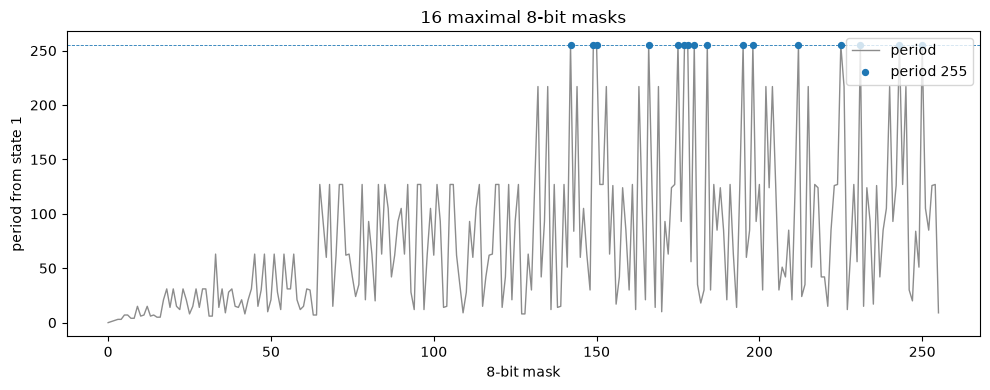

In [3]:
masks8 = list(range(256))
periods8 = [period(mask, 8) for mask in masks8]
maximal8 = [mask for mask, steps in zip(masks8, periods8) if steps == 255]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(masks8, periods8, color="0.55", linewidth=1, label="period")
ax.scatter(maximal8, [255] * len(maximal8), color="C0", s=18, zorder=3, label="period 255")
ax.axhline(255, color="C0", linewidth=0.6, linestyle="--")
ax.set_xlabel("8-bit mask")
ax.set_ylabel("period from state 1")
ax.set_title("%d maximal 8-bit masks" % len(maximal8))
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()


In [4]:
def serial_chi2(values, shift=1, nbits=2):
    """Chi-square of successive (value>>shift) & ((1<<nbits)-1) pairs."""
    size = 1 << nbits
    field = size - 1
    counts = [0] * (size * size)
    pairs = len(values) - 1
    for i in range(pairs):
        a = (values[i] >> shift) & field
        b = (values[i + 1] >> shift) & field
        counts[a * size + b] += 1
    expected = pairs / float(size * size)
    return sum((c - expected) ** 2 / expected for c in counts)


matches8 = []
for mask in range(256):
    if period(mask, 8) != 255:
        continue
    values = galois_sequence(mask, count=255, bits=8)
    matches8.append((
        "0x%02X" % mask,
        mask.bit_count(),
        f"{mask:08b}",
        lag_correlation(values, lag=1),
        lag_correlation(values, lag=2),
        lag_correlation(values, lag=3),
        lag_correlation(values, lag=4),
    ))

# Controls: xorshift8, shuffled 1..255, and whitened Galois 0xFA.
import random

seed = 1
xorshift_seq = []
for _ in range(255):
    x = seed
    x ^= (x << 3) & 255
    x ^= (x >> 5) & 255
    x ^= (x << 4) & 255
    seed = x
    xorshift_seq.append(x)

shuffled = list(range(1, 256))
random.shuffle(shuffled)

whitened = [
    (value ^ i) & 0xFF
    for i, value in enumerate(galois_sequence(0xFA, count=255, bits=8))
]

for name, values in (
    ("xorshift8", xorshift_seq),
    ("shuffle", shuffled),
    ("whitened", whitened),
):
    matches8.append((
        name,
        0,
        name,
        lag_correlation(values, lag=1),
        lag_correlation(values, lag=2),
        lag_correlation(values, lag=3),
        lag_correlation(values, lag=4),
    ))

matches8.sort(key=lambda item: (item[1], item[0]))
print("%d rows: maximal 8-bit masks plus xorshift8, shuffle, whitened.\n" % len(matches8))
print("%-10s | %-8s | %-10s | %-8s | %-8s | %-8s | %8s" % ("Name", "Weight", "Binary Tap", "lag-1", "lag-2", "lag-3", "lag-4"))
print("-" * 72)
for name, weight, bits, corr1, corr2, corr3, corr4 in matches8:
    if len(bits) == 8 and bits.replace("0", "").replace("1", "") == "":
        grouped = "%s %s" % (bits[:4], bits[4:])
    else:
        grouped = bits
    print(
        "%-10s | %-8d | %-10s | %+8.4f | %+8.4f | %+8.4f | %+8.4f"
        % (name, weight, grouped, corr1, corr2, corr3, corr4)
    )


19 rows: maximal 8-bit masks plus xorshift8, shuffle, whitened.

Name       | Weight   | Binary Tap | lag-1    | lag-2    | lag-3    |    lag-4
------------------------------------------------------------------------
shuffle    | 0        | shuffle    |  -0.0134 |  +0.1790 |  -0.1001 |  +0.1114
whitened   | 0        | whitened   |  +0.0378 |  -0.0027 |  -0.0447 |  +0.0363
xorshift8  | 0        | xorshift8  |  -0.0118 |  -0.0118 |  -0.0059 |  -0.0118
0x8E       | 4        | 1000 1110  |  +0.4922 |  +0.2402 |  +0.0905 |  -0.0081
0x95       | 4        | 1001 0101  |  +0.4747 |  +0.1809 |  -0.0103 |  -0.0118
0x96       | 4        | 1001 0110  |  +0.4744 |  +0.1927 |  -0.0044 |  -0.0088
0xA6       | 4        | 1010 0110  |  +0.4033 |  +0.0149 |  +0.0000 |  -0.0088
0xB1       | 4        | 1011 0001  |  +0.3813 |  -0.0051 |  -0.0103 |  -0.0118
0xB2       | 4        | 1011 0010  |  +0.3811 |  +0.0060 |  +0.0000 |  +0.0000
0xB4       | 4        | 1011 0100  |  +0.3799 |  +0.0032 |  +0.0178 |  +

In [5]:
galoisSeed=1
#galoisTap=0xB8

galoisTap=0xFA
marsagliaSeed=1



def galoisRng():
    """Full-period (or count) Galois right-shift states after seed."""
    state_mask = 255
    global galoisSeed
    state = galoisSeed & state_mask
    galoisSeed = ((galoisSeed >> 1) ^ (galoisTap if (galoisSeed & 1) else 0)) & state_mask
    return galoisSeed

def xorshift8():
    global marsagliaSeed
    x=marsagliaSeed
    x ^= (x << 3) & 255;
    x ^= (x >> 5) & 255;
    x ^= (x << 4) & 255;
    marsagliaSeed = x 
    return marsagliaSeed


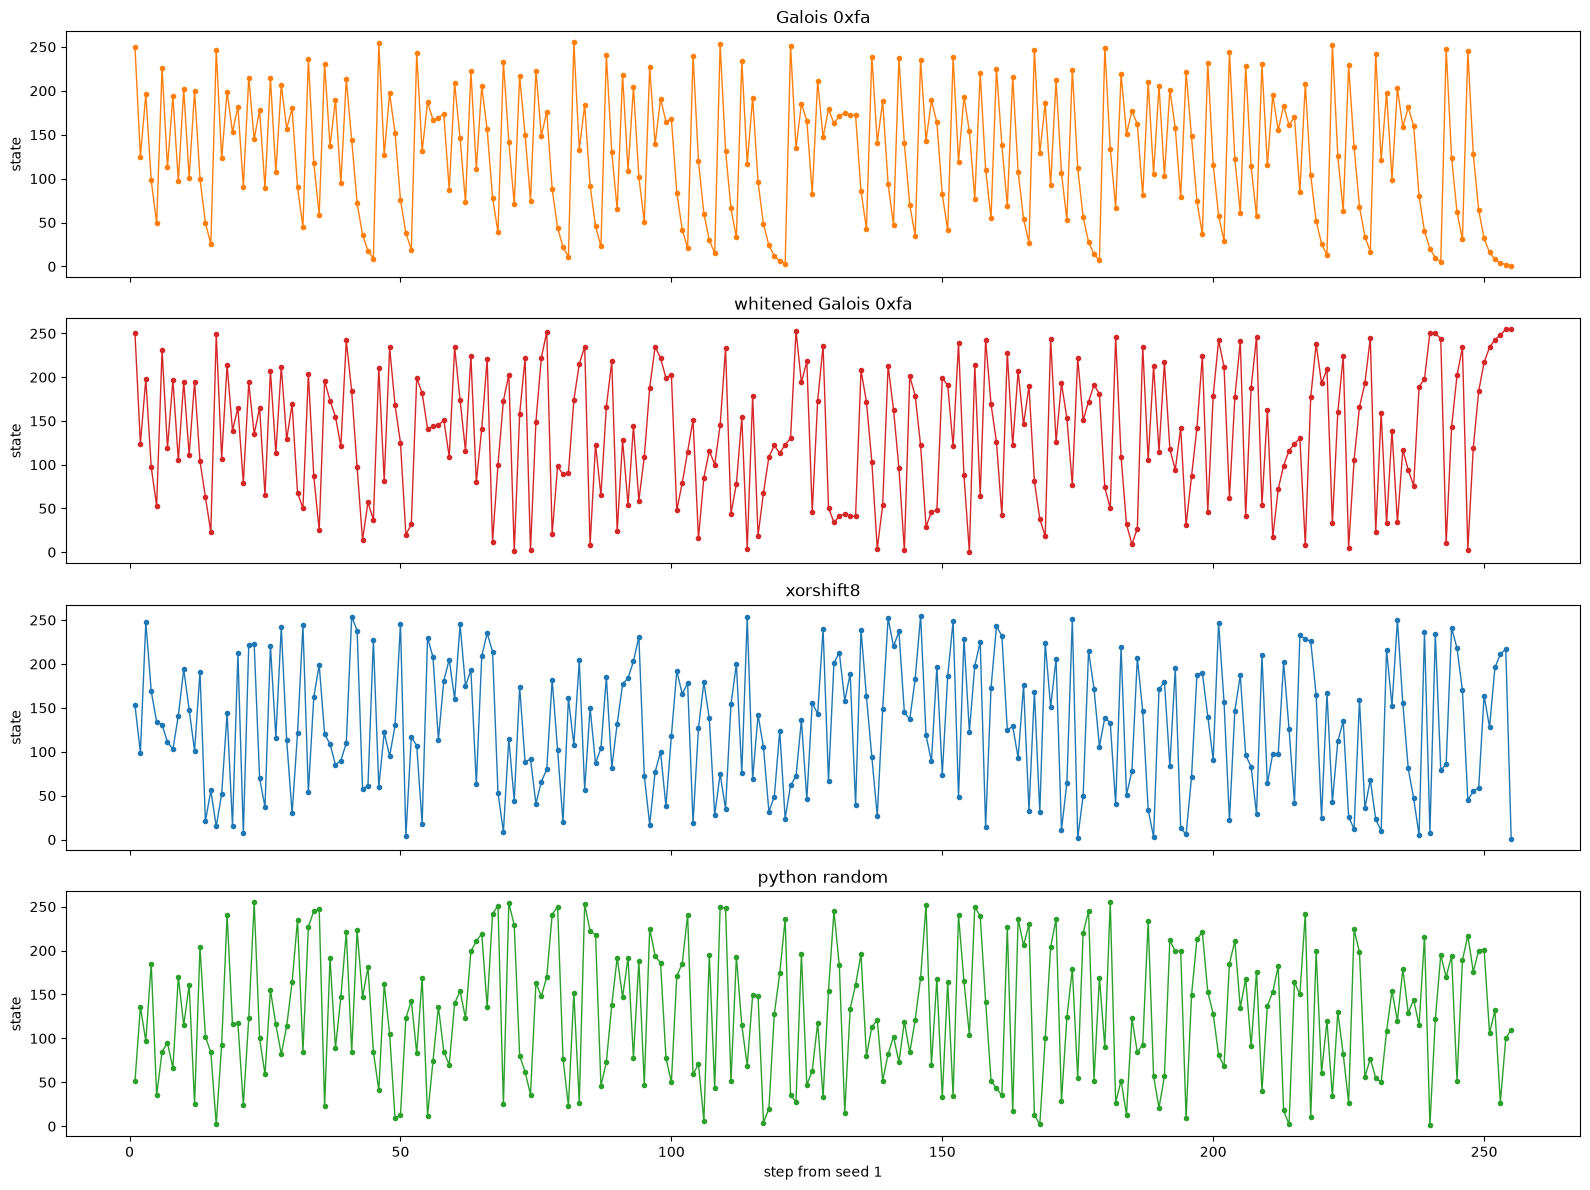

In [6]:
import random
galoisTap=0xFA
steps = list(range(1, 256))
galoisSeed=1
seq_galois = [galoisRng() for _ in range(255)]
galoisSeed=1
seq_galois_whitened = [(galoisRng()^ whitening ) & 0xFF for whitening in range(255)]
marsagliaSeed=1
seq_xorshift = [xorshift8() for _ in range(255)]
seq_python = [random.randint(1, 255) for _ in range(255)]

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
series = [
    (seq_galois, "C1", f"Galois {hex(galoisTap)}"),
    (seq_galois_whitened, "C3", f"whitened Galois {hex(galoisTap)}"),
    (seq_xorshift, "C0", "xorshift8"),
    (seq_python, "C2", "python random"),
]
for ax, (values, color, title) in zip(axes, series):
    ax.plot(steps, values, linewidth=1, color=color,marker='.')
    ax.set_title(title)
    ax.set_ylabel("state")
axes[-1].set_xlabel("step from seed 1")
fig.tight_layout()
plt.show()


In [7]:



def markov_probs(values, shift, nbits):
    """Transition probabilities of (value >> shift) & ((1 << nbits) - 1)."""
    size = 1 << nbits
    field = size - 1
    counts = [[0] * size for _ in range(size)]
    row_tot = [0] * size
    for i in range(len(values) - 1):
        a = (values[i] >> shift) & field
        b = (values[i + 1] >> shift) & field
        counts[a][b] += 1
        row_tot[a] += 1
    probs = []
    for a in range(size):
        denom = float(row_tot[a]) if row_tot[a] else 0.0
        probs.append([(counts[a][b] / denom) if denom else 0.0 for b in range(size)])
    return probs


def value_chi2(values, bits=8):
    """Chi-square of the 8-bit values against a uniform 0..255 distribution."""
    size = 1 << bits
    counts = [0] * size
    for value in values:
        counts[value & (size - 1)] += 1
    expected = len(values) / float(size)
    return sum((count - expected) ** 2 / expected for count in counts)


def fmt_markov(probs):
    return " ".join("%5.2f" % p for row in probs for p in row)


sequences = [
    (f"Galois {hex(galoisTap)}", seq_galois),
    (f"whitened Galois {hex(galoisTap)}", seq_galois_whitened),
    ("xorshift8", seq_xorshift),
    ("python random", seq_python),
]
print(
    "%-22s | %8s | %8s | %-23s | %s"
    % ("sequence", "lag-1", "chi2", "(x>>1)&1", "(x>>2)&3")
)
print("-" * 110)
for name, values in sequences:
    print(
        "%-22s | %+8.4f | %8.2f | %-23s | %s"
        % (
            name,
            lag_correlation(values),
            value_chi2(values),
            fmt_markov(markov_probs(values, 1, 1)),
            fmt_markov(markov_probs(values, 2, 2)),
        )
    )


sequence               |    lag-1 |     chi2 | (x>>1)&1                | (x>>2)&3
--------------------------------------------------------------------------------------------------------------
Galois 0xfa            |  -0.0043 |     1.00 |  0.50  0.50  0.50  0.50 |  0.50  0.00  0.50  0.00  0.50  0.00  0.50  0.00  0.00  0.50  0.00  0.50  0.00  0.50  0.00  0.50
whitened Galois 0xfa   |  +0.0378 |   229.89 |  0.47  0.53  0.54  0.46 |  0.21  0.31  0.30  0.17  0.30  0.20  0.22  0.28  0.29  0.18  0.24  0.29  0.31  0.24  0.19  0.26
xorshift8              |  -0.0118 |     1.00 |  0.49  0.51  0.50  0.50 |  0.24  0.26  0.24  0.26  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25
python random          |  +0.0070 |   266.04 |  0.51  0.49  0.56  0.44 |  0.27  0.27  0.34  0.12  0.26  0.26  0.27  0.21  0.29  0.22  0.30  0.18  0.20  0.31  0.27  0.22


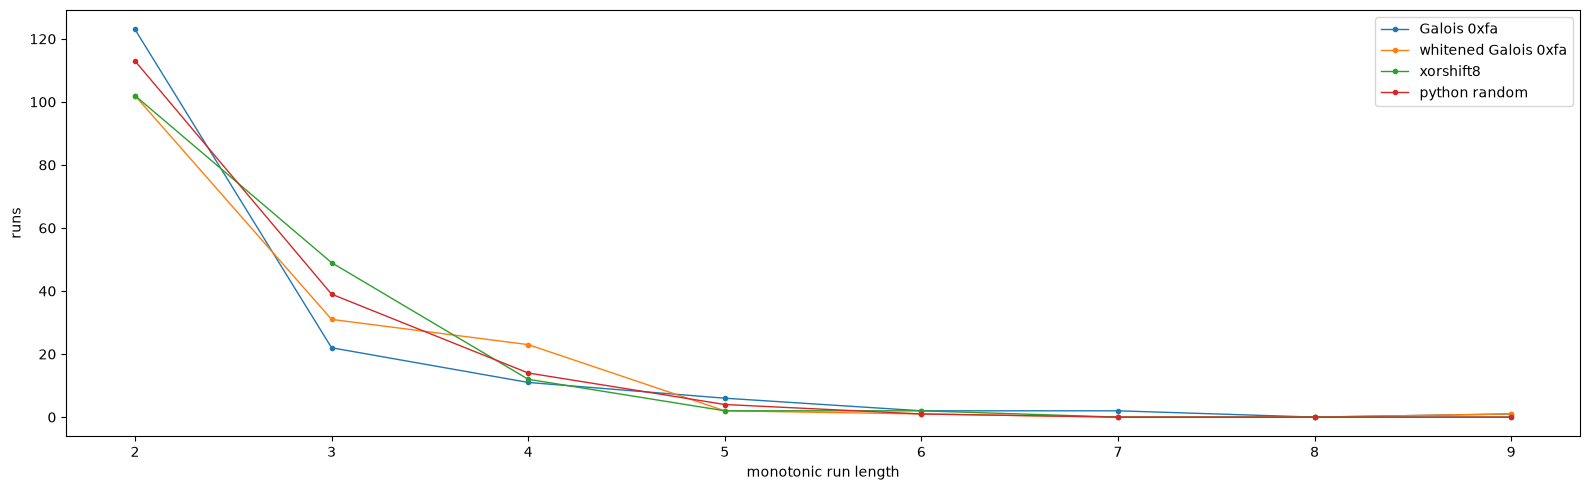

In [8]:
def monotonic_run_lengths(values):
    """Lengths of maximal non-decreasing or non-increasing stretches.

    Equals stay in the current run. The sample that turns around closes one
    run and opens the next.
    """
    n = len(values)
    if n < 2:
        return []
    lengths = []
    i = 0
    while i < n - 1:
        j = i + 1
        while j < n and values[j] == values[j - 1]:
            j += 1
        if j == n:
            lengths.append(n - i)
            break
        rising = values[j] > values[j - 1]
        while j < n and (values[j] >= values[j - 1] if rising else values[j] <= values[j - 1]):
            j += 1
        lengths.append(j - i)
        i = j - 1
    return lengths


named = [
    (f"Galois {hex(galoisTap)}", seq_galois),
    (f"whitened Galois {hex(galoisTap)}", seq_galois_whitened),
    ("xorshift8", seq_xorshift),
    ("python random", seq_python),
]
runs = [(name, monotonic_run_lengths(values)) for name, values in named]
longest = max(max(lengths) for _, lengths in runs)
xs = list(range(2, longest + 1))
fig, ax = plt.subplots(figsize=(16, 5))
for name, lengths in runs:
    counts = [0] * (longest + 1)
    for length in lengths:
        counts[length] += 1
    ax.plot(xs, [counts[x] for x in xs], marker=".", linewidth=1, label=name)
ax.set_xlabel("monotonic run length")
ax.set_ylabel("runs")
ax.legend()
fig.tight_layout()
plt.show()


## Maximal-tap 16×16 maps

For each of the 16 maximal 8-bit Galois masks, seed at 1 and walk all 255 nonzero states. Pixel `(x, y)` uses the lower/upper nibble of the sequence index `1..255`; grayscale is the RNG value itself. Index `0` stays black.

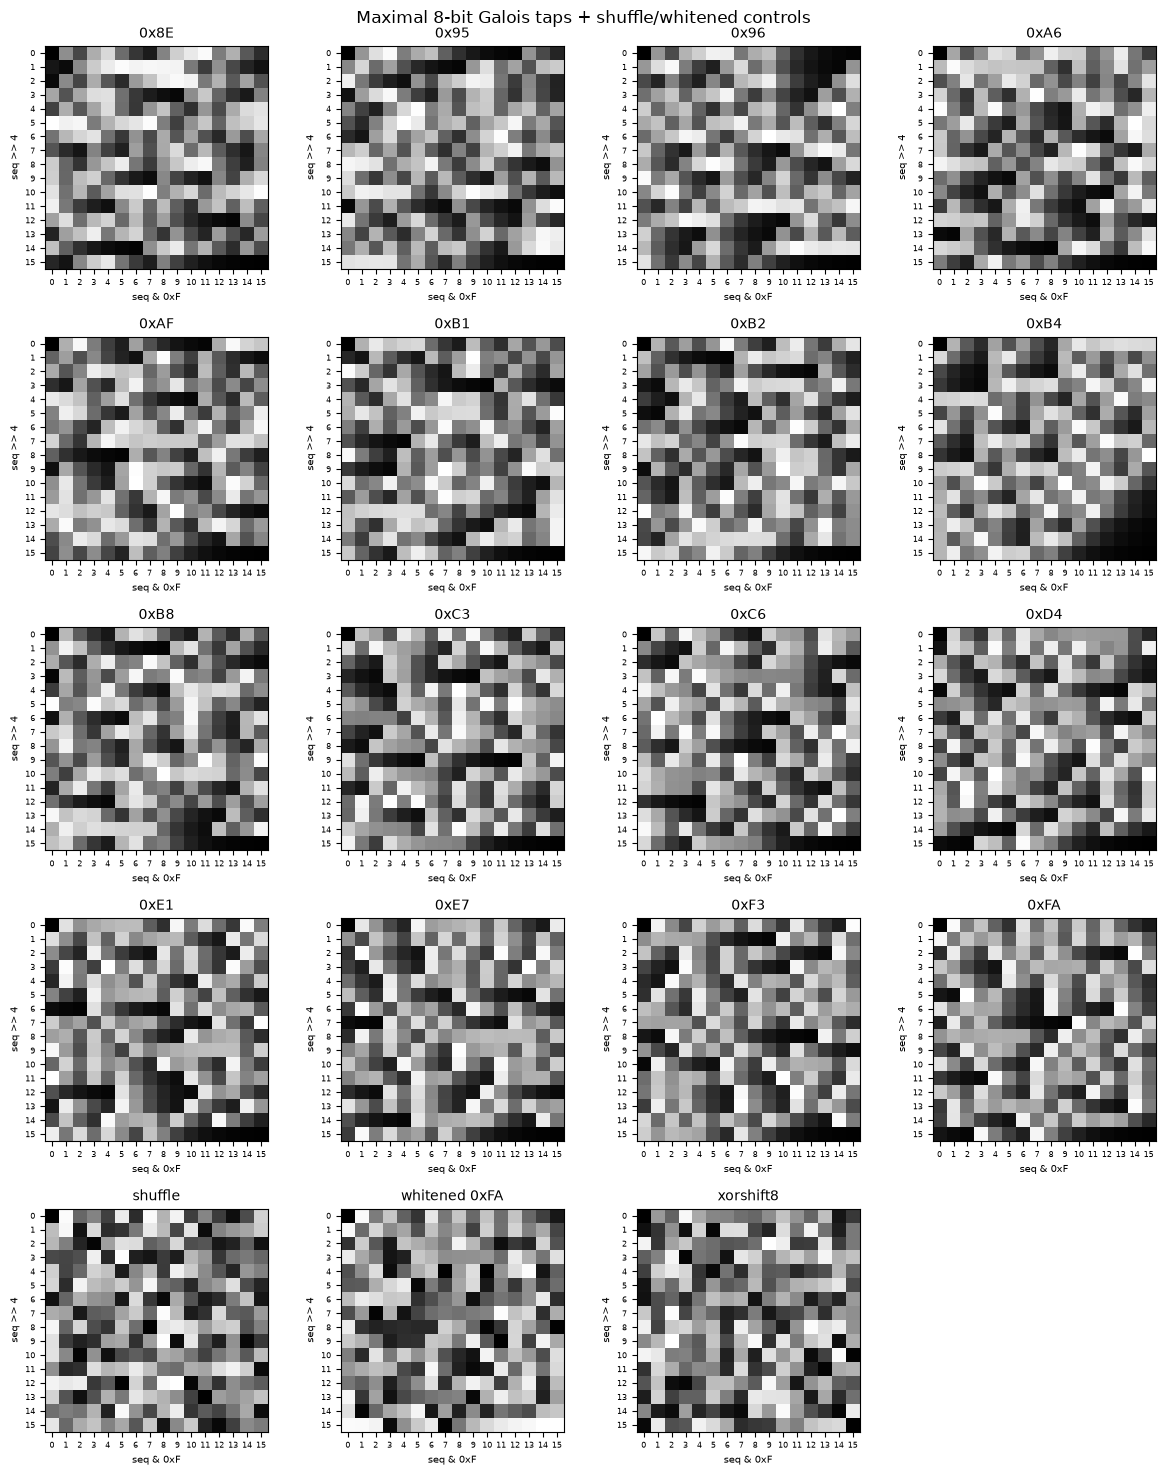

maximal masks: 0x8E 0x95 0x96 0xA6 0xAF 0xB1 0xB2 0xB4 0xB8 0xC3 0xC6 0xD4 0xE1 0xE7 0xF3 0xFA


In [9]:
def period8(mask):
    """Steps from state 1 back to itself for an 8-bit Galois mask."""
    state = 1
    for step in range(1, 256):
        state = ((state >> 1) ^ (mask if (state & 1) else 0)) & 0xFF
        if state == 1:
            return step
        if state == 0:
            return 0
    return 0


def galois_sequence8(mask, seed=1, count=255):
    """count states after seed for an 8-bit Galois right-shift LFSR."""
    state = seed & 0xFF
    mask &= 0xFF
    out = []
    for _ in range(count):
        state = ((state >> 1) ^ (mask if (state & 1) else 0)) & 0xFF
        out.append(state)
    return out


def sequence_image(values):
    """16x16 map: x=low nibble, y=high nibble of sequence index 1..255."""
    img = [[0] * 16 for _ in range(16)]
    for seq, value in enumerate(values, start=1):
        x = seq & 0x0F
        y = (seq >> 4) & 0x0F
        img[y][x] = value
    return img


maximal8 = [mask for mask in range(256) if period8(mask) == 255]
assert len(maximal8) == 16, "expected 16 maximal 8-bit masks, got %d" % len(maximal8)

control = list(range(1, 256))
random.shuffle(control)
whitened = [(value ^ i) & 0xFF for i, value in enumerate(galois_sequence8(0xFA))]
series = [("0x%02X" % mask, galois_sequence8(mask)) for mask in maximal8]
series.append(("shuffle", control))
series.append(("whitened 0xFA", whitened))
marsagliaSeed = 1
xorshift_seq = [xorshift8() for _ in range(255)]
series.append(("xorshift8", xorshift_seq))

fig, axes = plt.subplots(5, 4, figsize=(12, 15))
for ax, (title, values) in zip(axes.flat, series):
    img = sequence_image(values)
    ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(16))
    ax.set_yticks(range(16))
    ax.tick_params(labelsize=6)
    ax.set_xlabel("seq & 0xF", fontsize=7)
    ax.set_ylabel("seq >> 4", fontsize=7)
for ax in axes.flat[len(series):]:
    ax.set_visible(False)
fig.suptitle("Maximal 8-bit Galois taps + shuffle/whitened controls", fontsize=12)
fig.tight_layout()
fig.savefig("maximal-8-bit-galois-taps.png", dpi=150, bbox_inches="tight")
plt.show()

print("maximal masks:", " ".join("0x%02X" % m for m in maximal8))

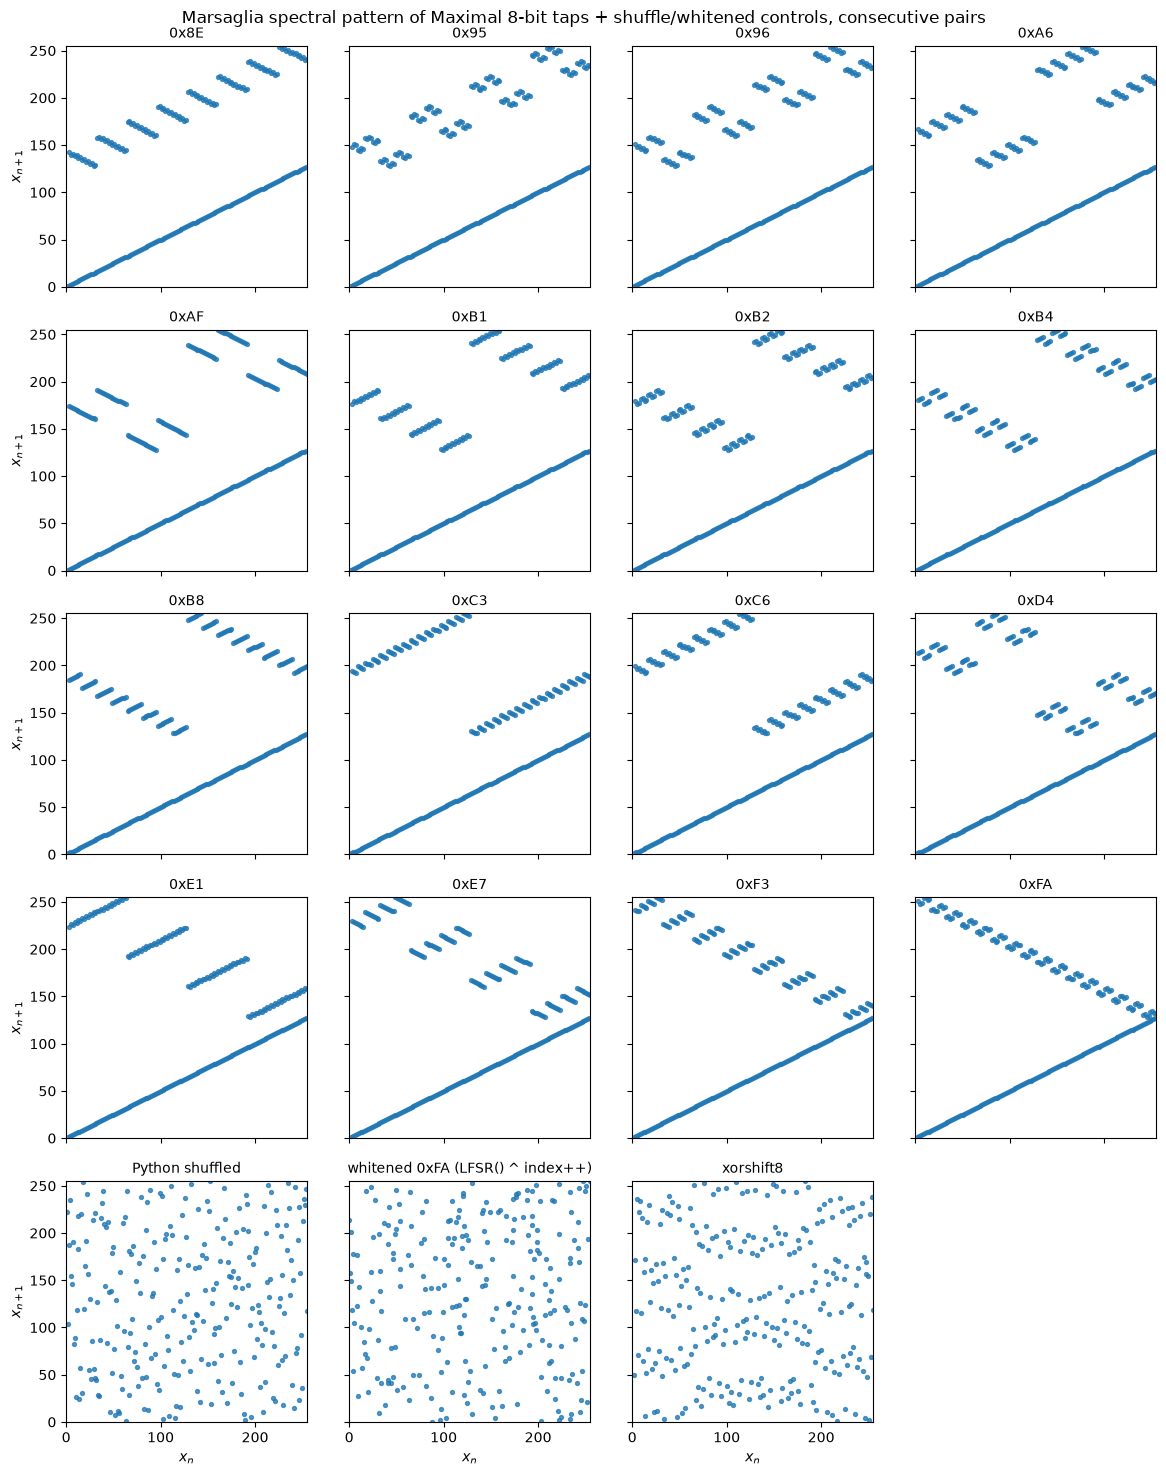

In [10]:
# Consecutive pairs (x_n, x_{n+1}) for every maximal 8-bit Galois tap,
# plus a shuffled 1..255 control from Python's random.
# A lattice or set of lines is the Marsaglia spectral pattern of a linear generator.
import random

masks = [mask for mask in range(256) if period(mask, 8) == 255]
control = list(range(1, 256))
random.shuffle(control)
whitened = [(value ^ i) & 0xFF for i, value in enumerate(galois_sequence(0xFA, count=255, bits=8))]
series = [("0x%02X" % mask, galois_sequence(mask, count=255, bits=8)) for mask in masks]
series.append(("Python shuffled", control))
series.append(("whitened 0xFA (LFSR() ^ index++)", whitened))
marsagliaSeed = 1
xorshift_seq = [xorshift8() for _ in range(255)]
series.append(("xorshift8", xorshift_seq))

fig, axes = plt.subplots(5, 4, figsize=(12, 15), sharex=True, sharey=True)
for ax, (title, values) in zip(axes.ravel(), series):
    ax.scatter(values[:-1], values[1:], s=8, alpha=0.75)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 255)
    ax.set_ylim(0, 255)
    ax.set_aspect("equal")
for ax in axes.ravel()[len(series):]:
    ax.set_visible(False)
for ax in axes[-1]:
    if ax.get_visible():
        ax.set_xlabel(r"$x_n$")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$x_{n+1}$")
fig.suptitle("Marsaglia spectral pattern of Maximal 8-bit taps + shuffle/whitened controls, consecutive pairs", fontsize=12)
fig.tight_layout()
fig.savefig("Marsaglia-spectral-pattern-maximal-8-bit-galois-taps.png", dpi=150, bbox_inches="tight")
plt.show()
